# Imports

In [1]:
import pickle

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from category_encoders import TargetEncoder

from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
plt.style.use('fivethirtyeight')

# Additional methods

## Preprocessing

### Filling NaNs

In [3]:
def fill_data_median(data: pd.DataFrame, columns_with_na: str | list) -> pd.DataFrame:
    if type(columns_with_na) is str:
        columns_with_na = [columns_with_na]
    medians = data[columns_with_na].median(axis = 0).transpose()
    filled_columns = data[columns_with_na].fillna(value=medians)
    return pd.concat([data.drop(columns_with_na, axis=1), filled_columns], axis=1)

In [4]:
def fill_data_mean(data: pd.DataFrame, columns_with_na: str | list) -> pd.DataFrame:
    if type(columns_with_na) is str:
        columns_with_na = [columns_with_na]
    medians = data[columns_with_na].mean(axis = 0).transpose()
    filled_columns = data[columns_with_na].fillna(value=medians)
    return pd.concat([data.drop(columns_with_na, axis=1), filled_columns], axis=1)

In [5]:
def fill_data_mode(data: pd.DataFrame, columns_with_na: str | list) -> pd.DataFrame:
    filled_data = data.copy()
    if type(columns_with_na) is str:
        columns_with_na = [columns_with_na]
    for column in columns_with_na:
        mode = filled_data[column].mode()[0]
        filled_data[column] = filled_data[column].fillna(mode)
    return filled_data

## Profile

In [6]:
class Profile:

    def __init__(self, form):
        self.age = int(form['age'])
        self.month_income = int(form['month_income'])
        self.employment_length = int(form['employment_length'])
        self.home_ownership = form['home_ownership']
        self.loan_intent = form['loan_intent']
        self.loan_amount = int(form['loan_amount'])
        self.loan_interest_rate = int(form['loan_interest_rate'])
        self.previous_loans = int(form['previous_loans'])
        self.previous_default = form['previous_default']
        self.loan_grade = form['loan_grade']

    def get_dictionary(self):
        dictionary = {
            'age': self.age,
            'month_income': self.month_income,
            'employment_length': self.employment_length,
            'home_ownership': self.home_ownership,
            'loan_intent': self.loan_intent,
            'loan_amount': self.loan_amount,
            'loan_interest_rate': self.loan_interest_rate,
            'previous_loans': self.previous_loans,
            'previous_default': self.previous_default,
            'loan_grade': self.loan_grade
        }
        return dictionary

### Data transformer

In [7]:
class DatasetMetadata:
    def __init__(self):
        self.features = ['age', 'month_income', 'employment_length', 'home_ownership', 'loan_intent',
                         'loan_amount', 'loan_interest_rate', 'previous_loans', 'previous_default', 'loan_grade',
                         'loan_status']
        self.target_feature = 'loan_status'
        self.input_features = [f for f in self.features if f != self.target_feature]
        self.replace_dict = {
            'previous_default': {'YES': 1, 'NO': 0},
            'home_ownership': {'OTHER': 0, 'RENT': 0, 'MORTGAGE': 1, 'OWN': 2},
            'loan_grade': {'G': 0, 'F': 1, 'E': 2, 'D': 3, 'C': 4, 'B': 5, 'A': 6}
        }
        self.features_to_encode = ['loan_intent']

In [8]:
class DataTransformer:
    def __init__(self, dataset_metadata):
        self.ds = dataset_metadata

        self.target_encoder = TargetEncoder(cols=self.ds.features_to_encode)
        self.standard_scaler = StandardScaler()

    def transform(self, X, is_dataset=True):
        X_copy = X.copy()

        for column, mapping in self.ds.replace_dict.items():
            X_copy[column] = X_copy[column].replace(mapping)

        if is_dataset:
            self.target_encoder.fit(X_copy[self.ds.input_features], X_copy[self.ds.target_feature])
            X_copy[self.ds.input_features] = self.target_encoder.transform(X_copy[self.ds.input_features])

            self.standard_scaler.fit(X_copy[self.ds.input_features])
            X_copy[self.ds.input_features] = self.standard_scaler.transform(X_copy[self.ds.input_features])
        else:
            X_copy = self.target_encoder.transform(X_copy)
            X_copy[self.ds.input_features] = self.standard_scaler.transform(X_copy)

        return X_copy

    def process_profile(self, profile: Profile) -> dict:
        profile_df = pd.DataFrame.from_dict(profile.get_dictionary(), orient='index').T

        processed_profile = self.transform(profile_df, is_dataset=False)

        return processed_profile.to_dict(orient='records')[0]

# Dataset

In [9]:
df = pd.read_csv('./../dataset/credit_history.csv')
df.head()

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status
0,22,59000,123.0,RENT,PERSONAL,35000,16.02,3,YES,D,0
1,21,9600,5.0,OWN,EDUCATION,1000,11.14,2,NO,B,1
2,25,9600,1.0,MORTGAGE,MEDICAL,5500,12.87,3,NO,C,0
3,23,65500,4.0,RENT,MEDICAL,35000,15.23,2,NO,C,0
4,24,54400,8.0,RENT,MEDICAL,35000,14.27,4,YES,C,0


In [10]:
df.sample(5)

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status
27678,28,160000,12.0,OWN,PERSONAL,23000,11.83,8,NO,B,1
12215,23,80000,3.0,MORTGAGE,EDUCATION,6000,5.99,4,NO,A,1
26482,28,103200,7.0,MORTGAGE,EDUCATION,9000,9.88,6,NO,B,1
25296,29,83000,13.0,MORTGAGE,HOME_IMPROVEMENT,7500,8.90,6,NO,A,1
25230,29,75840,5.0,OWN,HOME_IMPROVEMENT,25000,21.27,6,NO,G,0


In [11]:
len(df.drop_duplicates()), len(df)

(32416, 32581)

## Feature analysis

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 32581 non-null  int64  
 1   month_income        32581 non-null  int64  
 2   employment_length   31686 non-null  float64
 3   home_ownership      32581 non-null  object 
 4   loan_intent         32581 non-null  object 
 5   loan_amount         32581 non-null  int64  
 6   loan_interest_rate  29465 non-null  float64
 7   previous_loans      32581 non-null  int64  
 8   previous_default    32581 non-null  object 
 9   loan_grade          32581 non-null  object 
 10  loan_status         32581 non-null  int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 2.7+ MB


Подивимось на колонки в яких містяться `NaN`:

In [13]:
columns_with_na = df.columns[df.isna().any()].tolist()
columns_with_na

['employment_length', 'loan_interest_rate']

### `age`

In [14]:
np.sort(df['age'].unique())

array([ 20,  21,  22,  23,  24,  25,  26,  27,  28,  29,  30,  31,  32,
        33,  34,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,
        46,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,  57,  58,
        59,  60,  61,  62,  63,  64,  65,  66,  67,  69,  70,  73,  76,
        78,  80,  84,  94, 123, 144], dtype=int64)

In [15]:
df['shifted_age'] = (df['age'] - df['age'].min() + 0.0001)
df['log_shifted_age'] = np.log(df['shifted_age'])

<Axes: ylabel='log_shifted_age'>

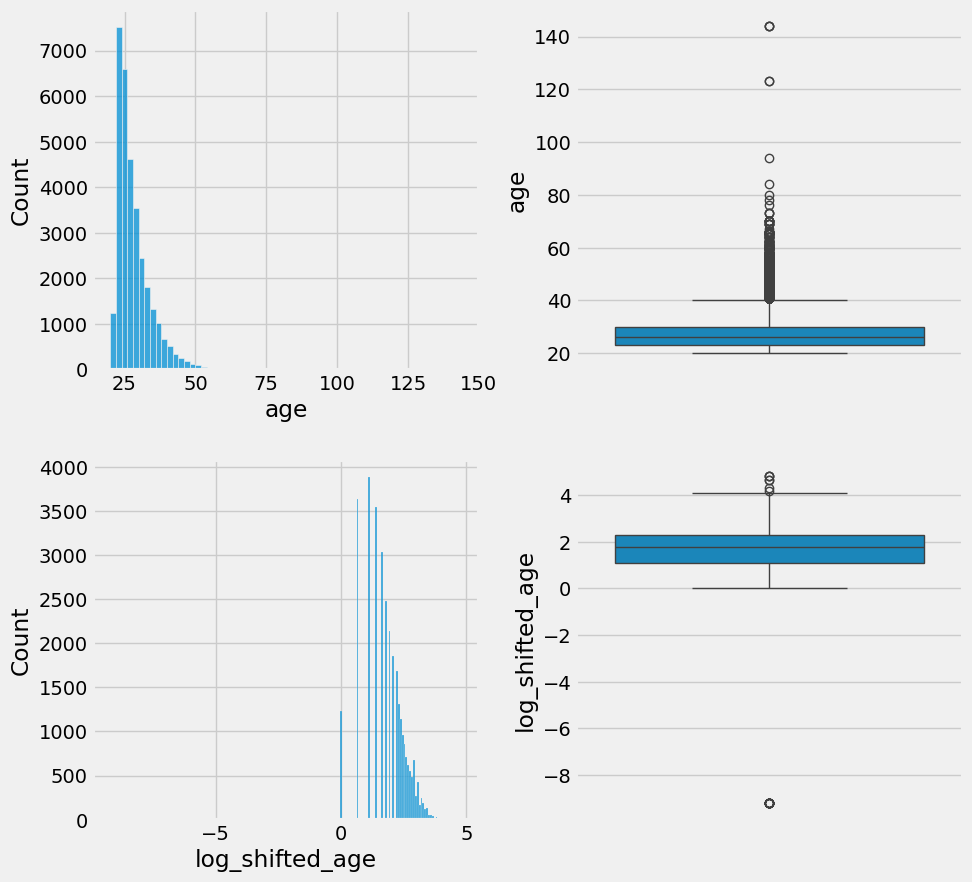

In [16]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['age'], binwidth=2, ax=axs[0, 0])
sns.histplot(data=df['log_shifted_age'], ax=axs[1, 0])
sns.boxplot(data=df['age'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_age'], ax=axs[1, 1])

In [17]:
mean, three_sigma = df['log_shifted_age'].mean(), 3 * df['log_shifted_age'].std()
mean, three_sigma

(1.751326097597005, 2.436667357626245)

In [18]:
df[np.abs(df['log_shifted_age'] - mean) > three_sigma].head()

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status,shifted_age,log_shifted_age
81,144,250000,4.0,RENT,VENTURE,4800,13.57,3,NO,C,1,124.0001,4.820282
183,144,200000,4.0,MORTGAGE,EDUCATION,6000,11.86,2,NO,B,1,124.0001,4.820282
575,123,80004,2.0,RENT,EDUCATION,20400,10.25,3,NO,B,1,103.0001,4.634730
747,123,78000,7.0,RENT,VENTURE,20000,NaN,4,NO,B,1,103.0001,4.634730
1313,20,64000,3.0,RENT,VENTURE,16000,15.31,4,YES,D,0,0.0001,-9.210340


In [19]:
np.sort(df[np.abs(df['log_shifted_age'] - mean) > three_sigma]['age'].unique())

array([ 20,  94, 123, 144], dtype=int64)

Таким чином, аномальними значеннями є `20` та більше `94`-х років. Ми можемо як видалити колонки, так і замінити їх на пропуски, після чого вставити на їх місце значення медіани по признаку.

В даному випадку видалимо всі записи, де клієнтм більше `90`-та років.

In [20]:
df.drop(df[df['age'] > 90].index, inplace = True) # Викидаємо людей який більше 90-та років

<Axes: ylabel='log_shifted_age'>

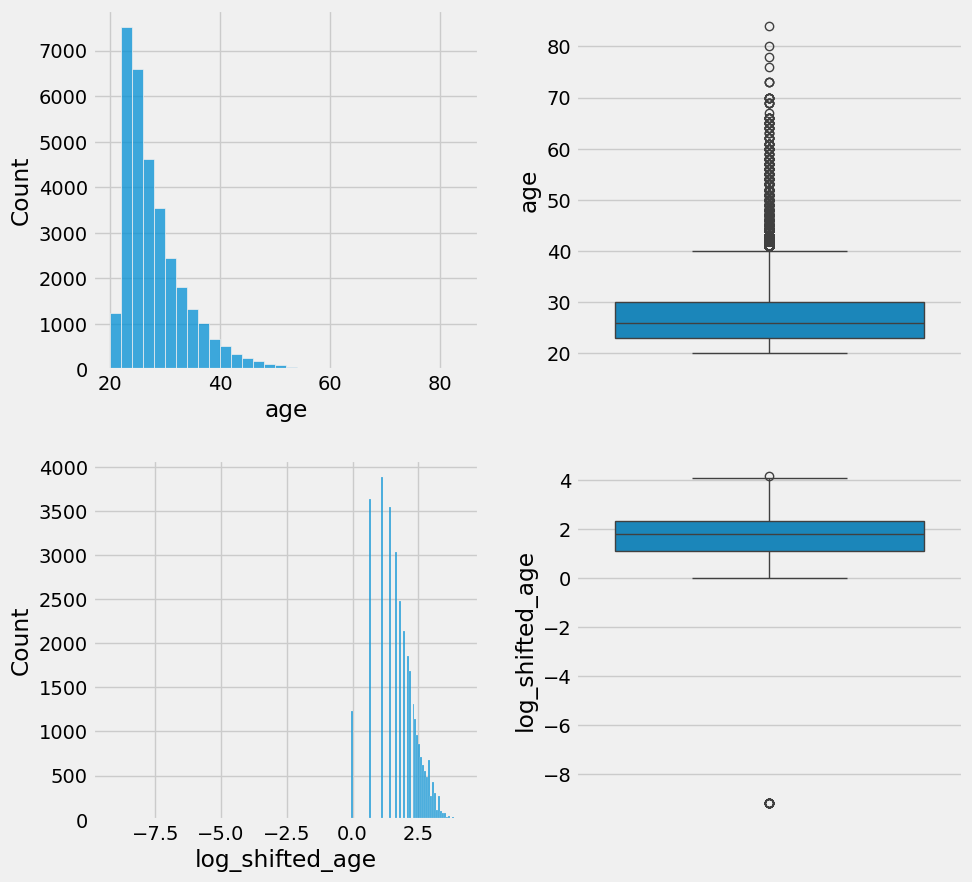

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['age'], binwidth=2, ax=axs[0, 0])
sns.histplot(data=df['log_shifted_age'], ax=axs[1, 0])
sns.boxplot(data=df['age'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_age'], ax=axs[1, 1])

In [22]:
df.drop(columns=['shifted_age', 'log_shifted_age'], inplace=True)

### `month_income`

In [23]:
df['month_income'].describe()

count    3.257500e+04
mean     6.588343e+04
std      5.253528e+04
min      4.000000e+03
25%      3.850000e+04
50%      5.500000e+04
75%      7.920000e+04
max      2.039784e+06
Name: month_income, dtype: float64

In [24]:
df['month_income'].median()

55000.0

In [25]:
np.sort(df['month_income'].unique())

array([   4000,    4080,    4200, ..., 1782000, 1900000, 2039784],
      dtype=int64)

In [26]:
df['shifted_income'] = (df['month_income'] - df['month_income'].min() + 0.0001)
df['log_shifted_income'] = np.log(df['shifted_income'])

<Axes: ylabel='log_shifted_income'>

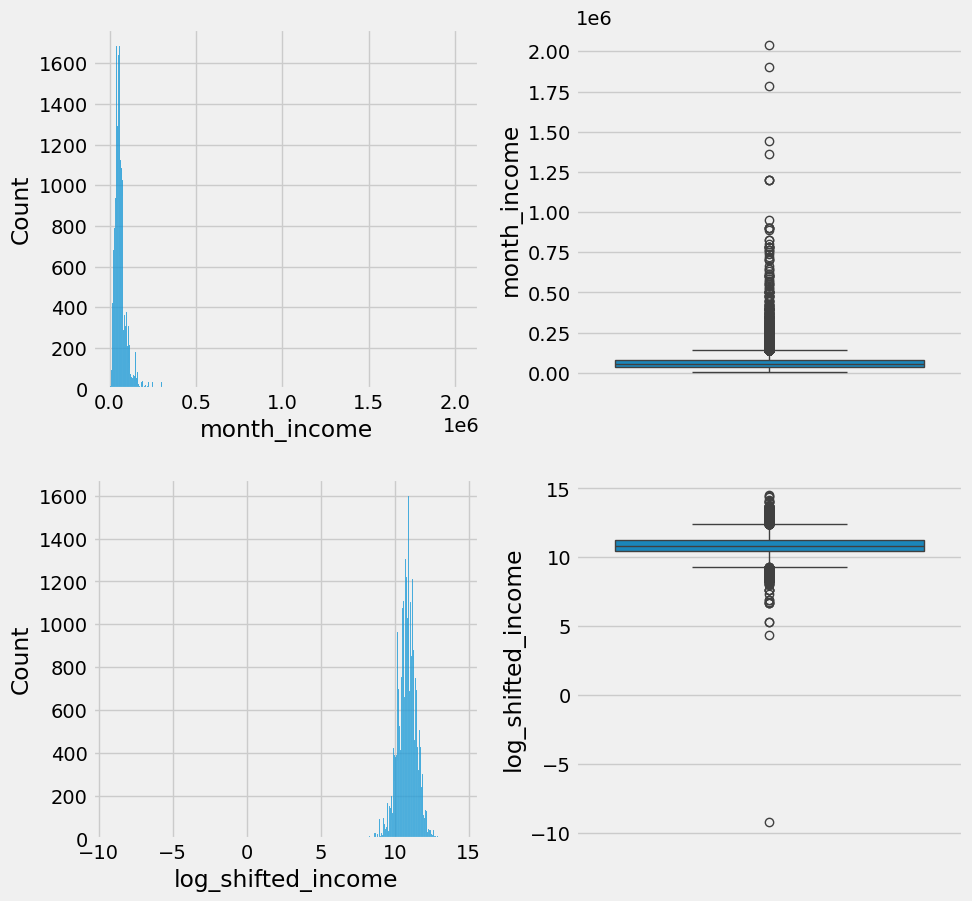

In [27]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['month_income'], ax=axs[0, 0])
sns.histplot(data=df['log_shifted_income'], ax=axs[1, 0])
sns.boxplot(data=df['month_income'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_income'], ax=axs[1, 1])

In [28]:
mean, three_sigma = df['log_shifted_income'].mean(), 3 * df['log_shifted_income'].std()
mean, three_sigma

(10.834000949895184, 1.9015258329693863)

In [29]:
df[np.abs(df['log_shifted_income'] - mean) > three_sigma].head()

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status,shifted_income,log_shifted_income
1,21,9600,5.0,OWN,EDUCATION,1000,11.14,2,NO,B,1,5600.0001,8.630522
2,25,9600,1.0,MORTGAGE,MEDICAL,5500,12.87,3,NO,C,0,5600.0001,8.630522
5,21,9900,2.0,OWN,VENTURE,2500,7.14,2,NO,A,0,5900.0001,8.682708
9,21,10000,6.0,OWN,VENTURE,1600,14.74,3,NO,D,0,6000.0001,8.699515
11,21,10000,2.0,OWN,HOME_IMPROVEMENT,4500,8.63,2,NO,A,0,6000.0001,8.699515


In [30]:
np.sort(df[np.abs(df['log_shifted_income'] - mean) > three_sigma]['month_income'].unique())

array([   4000,    4080,    4200,    4800,    4888,    5000,    5500,
          6000,    7000,    7200,    7500,    7800,    7904,    8000,
          8004,    8088,    8280,    8400,    8412,    8472,    8500,
          8628,    9000,    9081,    9192,    9600,    9732,    9840,
          9900,    9960,   10000,   10008,   10080,   10140,   10200,
         10380,   10400,   10500,   10560,   10636,   10668,   10800,
         10980,   11000,   11029,   11220,   11292,   11340,   11389,
         11440,   11476,   11520,  348000,  350000,  351699,  357000,
        360000,  365000,  370000,  371000,  372000,  375000,  381450,
        385000,  390000,  397800,  400000,  403750,  408000,  410000,
        415000,  420000,  425000,  430000,  444000,  445000,  450000,
        468000,  480000,  499800,  500000,  504000,  510000,  522000,
        528000,  540600,  550000,  552000,  564000,  572400,  584800,
        600000,  604000,  612000,  636000,  648000,  667680,  700000,
        703800,  708

Аналогічно як і з віком, маємо викиди значення яких є занадто малі та занадто великі значення зарплат клієнтів. Так само, можемо або видалити всі значення, або частину з них, або ж замінити їх на пропуски.

Видалимо всі записи де клієнти заробляють більше `300.000`.

In [31]:
df.drop(df[df['month_income'] > 300_000].index, inplace = True) # Викидаємо людей які заробляють більше 500.000

<Axes: ylabel='log_shifted_income'>

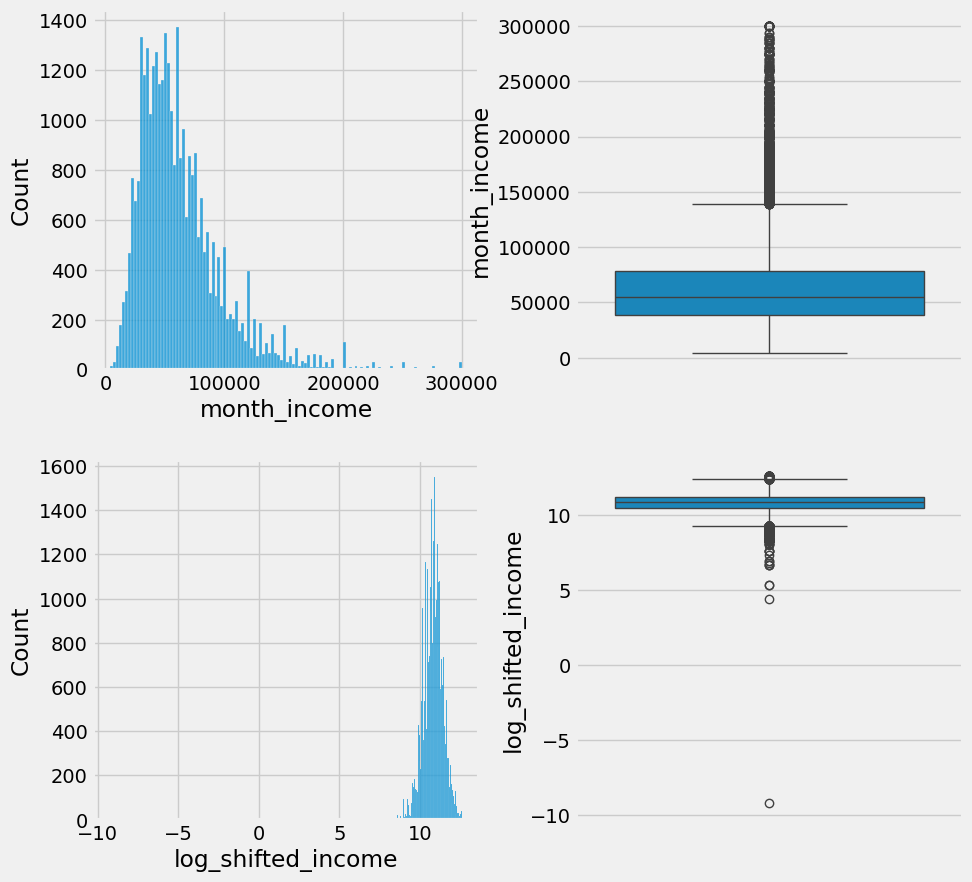

In [32]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['month_income'], ax=axs[0, 0])
sns.histplot(data=df['log_shifted_income'], ax=axs[1, 0])
sns.boxplot(data=df['month_income'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_income'], ax=axs[1, 1])

In [33]:
df.drop(columns=['shifted_income', 'log_shifted_income'], inplace=True)

### `employment_length`

In [34]:
np.sort(df['employment_length'].unique())

array([  0.,   1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.,  10.,
        11.,  12.,  13.,  14.,  15.,  16.,  17.,  18.,  19.,  20.,  21.,
        22.,  23.,  24.,  25.,  26.,  27.,  28.,  29.,  30.,  31.,  34.,
        38.,  41., 123.,  nan])

In [35]:
df['shifted_emp_length'] = (df['employment_length'] - df['employment_length'].min() + 0.5)
df['log_shifted_emp_length'] = np.log(df['shifted_emp_length'])

<Axes: ylabel='log_shifted_emp_length'>

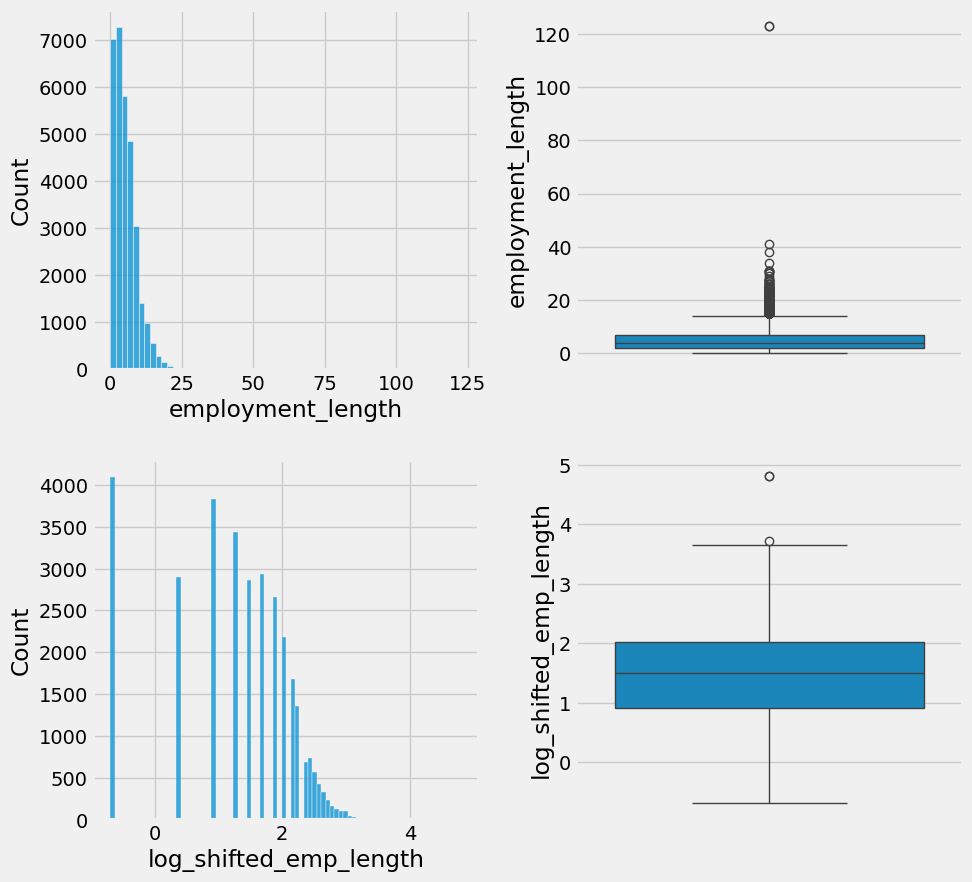

In [36]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['employment_length'], binwidth=2, ax=axs[0, 0])
sns.histplot(data=df['log_shifted_emp_length'], ax=axs[1, 0])
sns.boxplot(data=df['employment_length'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_emp_length'], ax=axs[1, 1])

In [37]:
mean, three_sigma = df['log_shifted_emp_length'].mean(), 3 * df['log_shifted_emp_length'].std()
mean, three_sigma

(1.292110769170099, 2.9369043541809283)

In [38]:
np.sort(df[np.abs(df['log_shifted_emp_length'] - mean) > three_sigma]['employment_length'].unique())

array([123.])

In [39]:
df[np.abs(df['log_shifted_emp_length'] - mean) > three_sigma]

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status,shifted_emp_length,log_shifted_emp_length
0,22,59000,123.0,RENT,PERSONAL,35000,16.02,3,YES,D,0,123.5,4.816241
210,21,192000,123.0,MORTGAGE,VENTURE,20000,6.54,4,NO,A,1,123.5,4.816241


In [40]:
df.loc[np.abs(df['log_shifted_emp_length'] - mean) > three_sigma, 'employment_length'] = np.nan # Замінюємо неможливий стаж роботи в 123 роки на NaN

<Axes: ylabel='log_shifted_emp_length'>

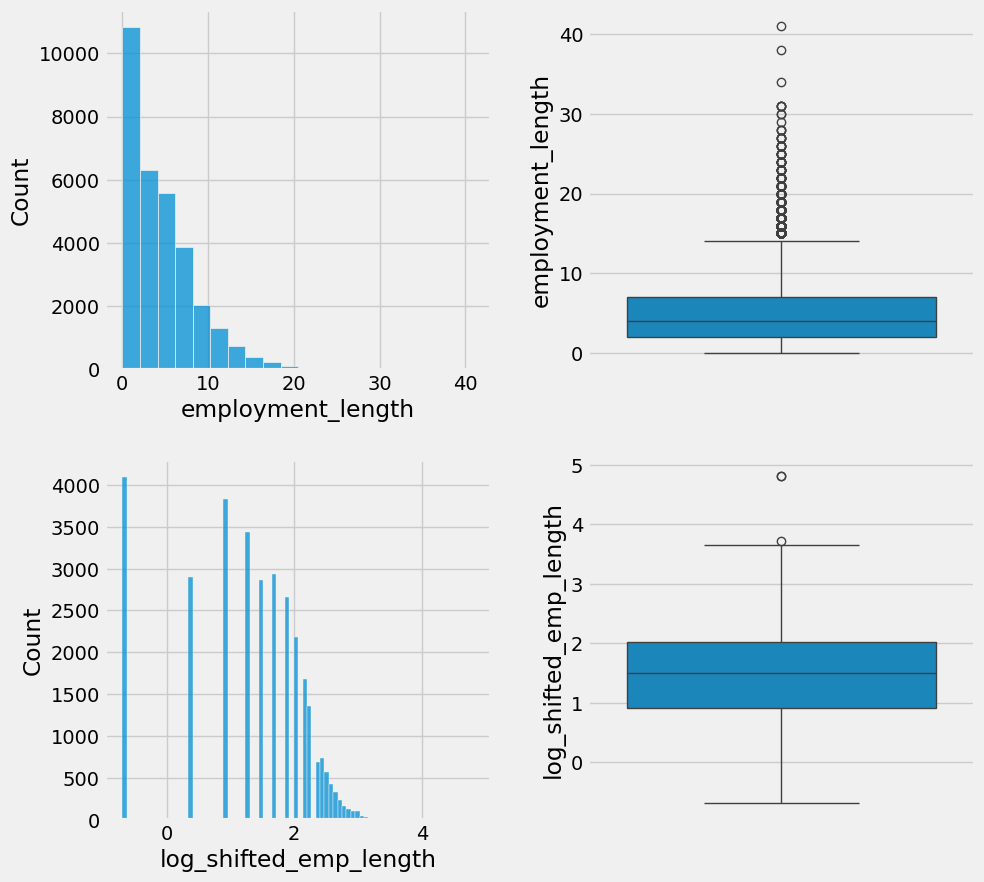

In [41]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['employment_length'], binwidth=2, ax=axs[0, 0])
sns.histplot(data=df['log_shifted_emp_length'], ax=axs[1, 0])
sns.boxplot(data=df['employment_length'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_emp_length'], ax=axs[1, 1])

In [42]:
df.drop(columns=['shifted_emp_length', 'log_shifted_emp_length'], inplace=True)

In [43]:
df['employment_length'].isna().sum(), len(df)

(895, 32438)

In [44]:
df = fill_data_median(df, 'employment_length')
df['employment_length'].isna().sum(), len(df)

(0, 32438)

### `home_ownership`

In [45]:
df['home_ownership'].unique()

array(['RENT', 'OWN', 'MORTGAGE', 'OTHER'], dtype=object)

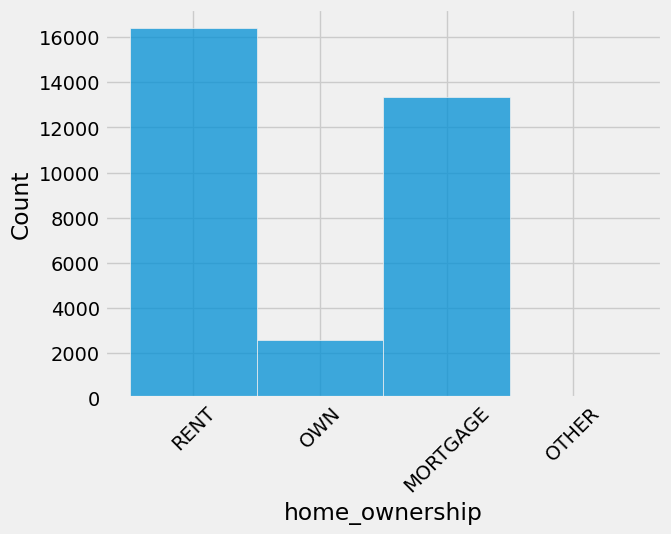

In [46]:
sns.histplot(data=df, x='home_ownership')
plt.tick_params(axis='x', rotation=45)

### `loan_intent`

In [47]:
df['loan_intent'].unique()

array(['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOME_IMPROVEMENT',
       'DEBT_CONSOLIDATION'], dtype=object)

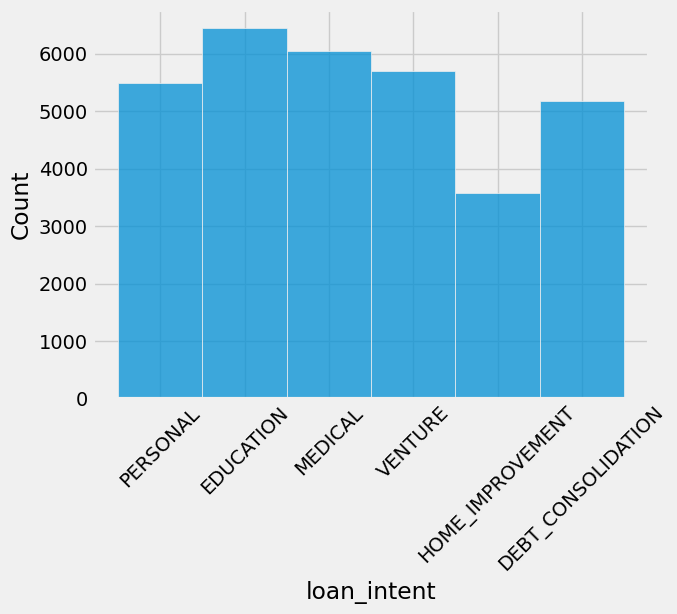

In [48]:
sns.histplot(data=df, x='loan_intent')
plt.tick_params(axis='x', rotation=45)

### `loan_interest_rate`

In [49]:
len(df['loan_interest_rate'].unique())

349

In [50]:
df['shifted_rate'] = (df['loan_interest_rate'] - df['loan_interest_rate'].min() + 0.01)
df['log_shifted_rate'] = np.log(df['shifted_rate'])

<Axes: ylabel='log_shifted_rate'>

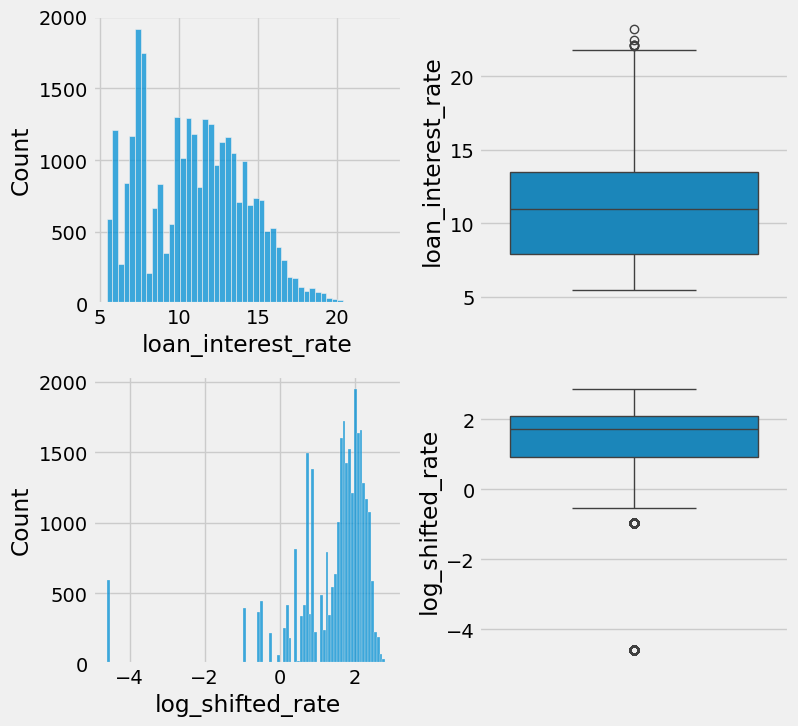

In [51]:
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['loan_interest_rate'], ax=axs[0, 0])
sns.histplot(data=df['log_shifted_rate'], ax=axs[1, 0])
sns.boxplot(data=df['loan_interest_rate'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_rate'], ax=axs[1, 1])

In [52]:
df.drop(columns=['shifted_rate', 'log_shifted_rate'], inplace=True)

In [53]:
df['loan_interest_rate'].isna().sum(), len(df)

(3100, 32438)

In [54]:
df = fill_data_mean(df, 'loan_interest_rate')
df['loan_interest_rate'].isna().sum(), len(df)

(0, 32438)

### `loan_amount`

In [55]:
len(df['loan_amount'].unique())

752

In [56]:
df['shifted_amount'] = (df['loan_amount'] - df['loan_amount'].min() + 0.01)
df['log_shifted_amount'] = np.log(df['shifted_amount'])

<Axes: ylabel='log_shifted_amount'>

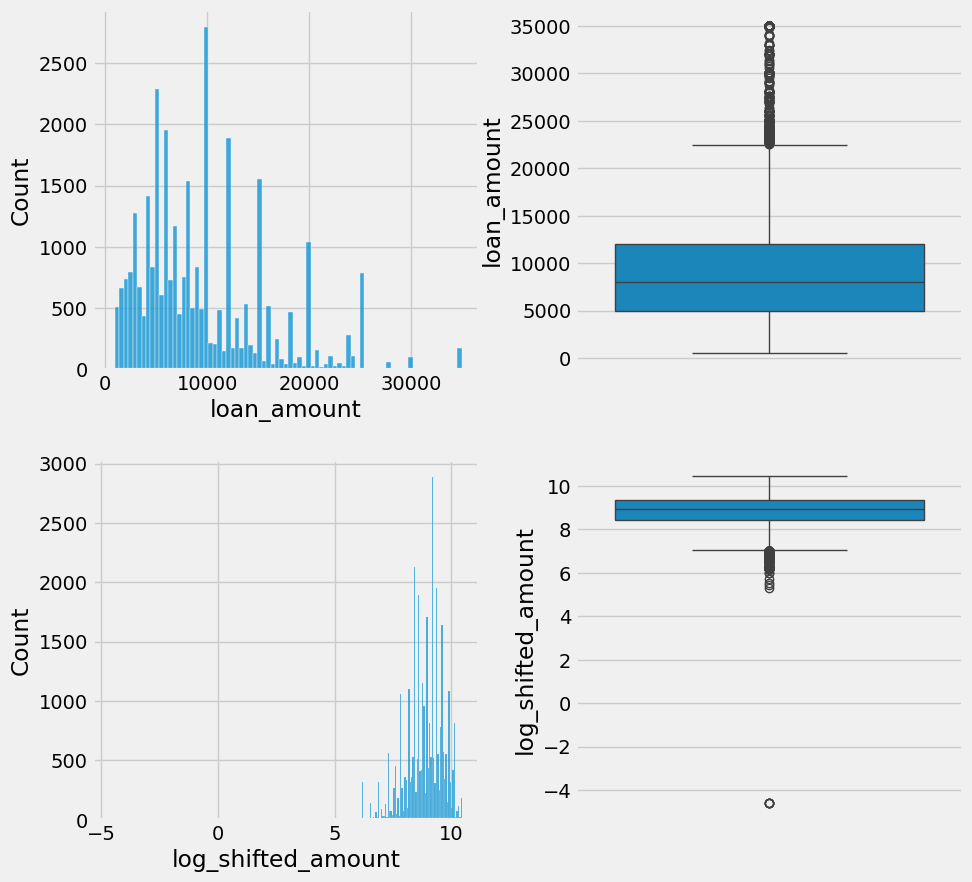

In [57]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.subplots_adjust(hspace=0.25, wspace=0.25)

sns.histplot(data=df['loan_amount'], ax=axs[0, 0])
sns.histplot(data=df['log_shifted_amount'], ax=axs[1, 0])
sns.boxplot(data=df['loan_amount'], ax=axs[0, 1])
sns.boxplot(data=df['log_shifted_amount'], ax=axs[1, 1])

In [58]:
df.drop(columns=['shifted_amount', 'log_shifted_amount'], inplace=True)

### `previous_loans`

In [59]:
np.sort(df['previous_loans'].unique())

array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18,
       19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30], dtype=int64)

<Axes: xlabel='previous_loans', ylabel='Count'>

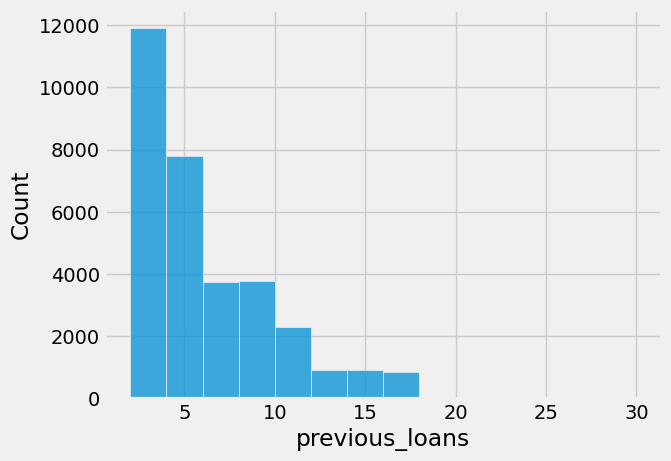

In [60]:
sns.histplot(data=df, x='previous_loans', binwidth=2)

### `previous_default`

In [61]:
np.sort(df['previous_default'].unique())

array(['NO', 'YES'], dtype=object)

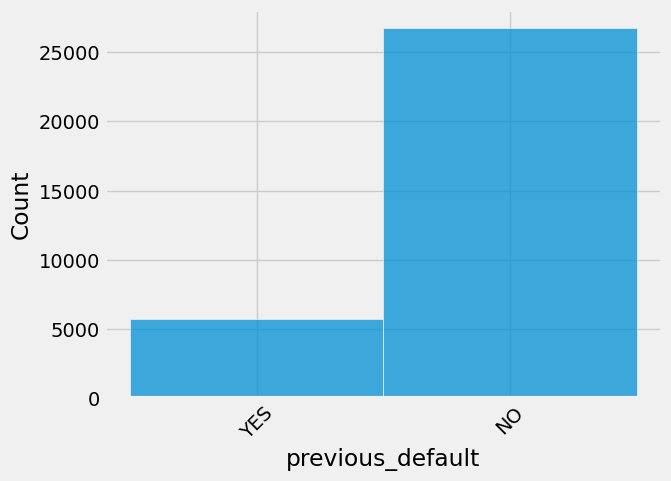

In [62]:
sns.histplot(data=df, x='previous_default', binwidth=0.5)
plt.tick_params(axis='x', rotation=45)

### `loan_grade`

In [63]:
np.sort(df['loan_grade'].unique())

array(['A', 'B', 'C', 'D', 'E', 'F', 'G'], dtype=object)

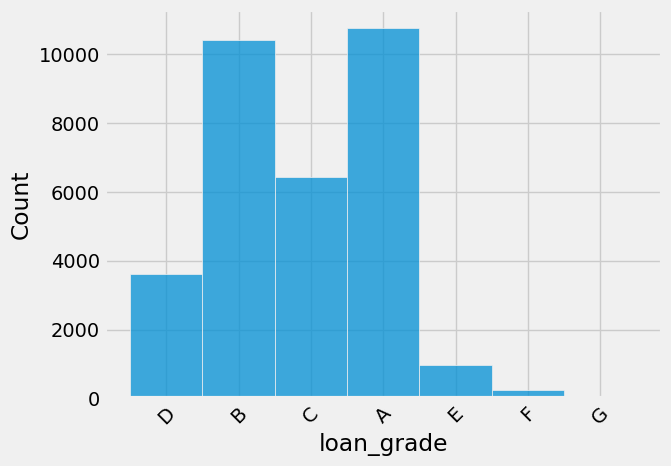

In [64]:
sns.histplot(data=df, x='loan_grade', binwidth=0.5)
plt.tick_params(axis='x', rotation=45)

### `loan_status`

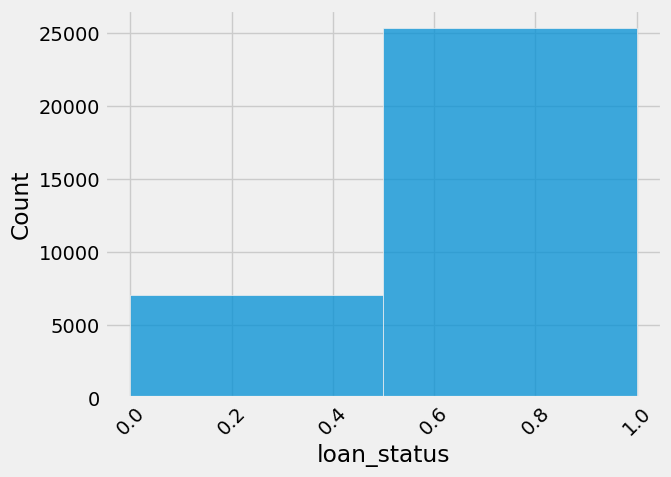

In [65]:
sns.histplot(data=df, x='loan_status', binwidth=0.5)
plt.tick_params(axis='x', rotation=45)

## Transformation

In [66]:
dsm = DatasetMetadata()
df = df[dsm.features]
df.head()

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status
0,22,59000,4.0,RENT,PERSONAL,35000,16.02,3,YES,D,0
1,21,9600,5.0,OWN,EDUCATION,1000,11.14,2,NO,B,1
2,25,9600,1.0,MORTGAGE,MEDICAL,5500,12.87,3,NO,C,0
3,23,65500,4.0,RENT,MEDICAL,35000,15.23,2,NO,C,0
4,24,54400,8.0,RENT,MEDICAL,35000,14.27,4,YES,C,0


In [67]:
dsm.features.copy().remove(dsm.target_feature)

In [68]:
transformer = DataTransformer(dsm)

df_transformed = transformer.transform(df)

df_transformed.sample(5)

,age,month_income,employment_length,home_ownership,loan_intent,loan_amount,loan_interest_rate,previous_loans,previous_default,loan_grade,loan_status
1286,-0.759608,-0.049448,0.565912,-0.897295,1.339004,1.024085,-1.141843,-0.937953,-0.462107,1.043759,1
20133,-0.110482,-0.927646,-0.692368,-0.897295,0.881880,-0.884359,-0.083994,-0.193942,-0.462107,0.186109,1
22189,0.700925,-0.941535,-0.440712,-0.897295,1.339004,-0.454959,-0.207301,0.798072,-0.462107,0.186109,1
14022,-0.597326,0.965502,-0.189056,0.676538,-0.924066,-0.248211,-0.330609,-0.689950,-0.462107,0.186109,1
10182,-0.435045,0.042806,1.069224,0.676538,-1.304800,-0.184596,0.318378,-0.937953,-0.462107,0.186109,1


In [69]:
df_transformed.to_csv('./../dataset/credit_history_transformed.csv', index=False)

In [71]:
with open('./../loan-processor/resources/data_transformer.pkl', 'wb') as file:
    pickle.dump(transformer, file)